In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt

In [22]:
PROJECT_ROOT = Path.cwd()

# If the notebook is running from the notebooks directory:
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "train.csv"

df = pd.read_csv(DATA_PATH)

## 1. Dataset Overview

### Research Question
What is the structure of the dataset, and what information does each feature contain?

### Objective
Understand the dataset's dimensions, feature definitions, and data types, and identify potential data quality issues that should be investigated before preprocessing and model development.

### Dataset Description
The Titanic dataset contains passenger information and the target variable indicating whether each passenger survived.

The following data dictionary is based on the official Kaggle documentation.

| Feature | Description | Values / Notes |
|---|---|---|
| `Survived` | Whether the passenger survived | 0 = No, 1 = Yes |
| `Pclass` | Ticket class; a proxy for socio-economic status | 1 = First, 2 = Second, 3 = Third |
| `Sex` | Passenger's sex | male / female |
| `Age` | Passenger's age in years | May contain fractional values |
| `SibSp` | Number of siblings and spouses aboard | Integer count |
| `Parch` | Number of parents and children aboard | Integer count |
| `Ticket` | Ticket number | Text / identifier |
| `Fare` | Passenger fare | Numeric |
| `Cabin` | Cabin number | Text / identifier |
| `Embarked` | Port of embarkation | C = Cherbourg, Q = Queenstown, S = Southampton |
| `PassengerId` | Passenger identifier | Unique identifier |

### Variable Notes
- `Pclass`: Represents ticket class and serves as a proxy for socio-economic status.
- `Age`: May contain fractional values, particularly for infants. Estimated ages may be recorded with a fractional component.
- `SibSp`: Includes siblings and spouses aboard; certain relationships, such as fiancés, are not included.
- `Parch`: Includes parents and children aboard. Some children travelled with a nanny and may therefore have `Parch = 0`.

In [23]:
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

display(df.head())
df.info()

overview = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
})

display(overview)

# Count fully duplicated rows
duplicate_count = df.duplicated().sum()
print(f"Number of fully duplicated rows: {duplicate_count}")

# Display duplicated rows, if any
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)])

Number of rows: 891
Number of columns: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


,missing_count,missing_percentage,unique_values
PassengerId,0,0.00,891
Survived,0,0.00,2
Pclass,0,0.00,3
Name,0,0.00,891
Sex,0,0.00,2
Age,177,19.87,88
SibSp,0,0.00,7
Parch,0,0.00,7
Ticket,0,0.00,681
Fare,0,0.00,248


Number of fully duplicated rows: 0


#### Findings

- **Feature types:**
  - Numerical: `Age`, `Fare`.
  - Categorical: `Survived`, `Pclass`, `Sex`, `Embarked`.
  - Count-based: `SibSp`, `Parch`.
  - Textual: `Name`, `Ticket`, `Cabin`.
  - Identifier: `PassengerId`.

- **Potential identifiers or derived features:**
  - `PassengerId`: unique identifier; investigate whether it can be excluded from model inputs.
  - `Name`: may allow extracting passenger titles.
  - `SibSp` and `Parch`: can be combined to derive `FamilySize`.

- **Initial data quality observations:**
  - `Age`: 177 missing values (19.87%).
  - `Cabin`: 687 missing values (77.10%).
  - `Embarked`: 2 missing values (0.22%).
  - All other columns have no missing values.
  - No fully duplicated records were found.

## 2. Target Distribution

### Research Question
Is the target variable, `Survived`, balanced between the two classes?

### Objective
Examine the distribution of the target classes to determine whether the dataset is imbalanced and whether class imbalance should be considered during model training and evaluation.

,Passenger Count,Percentage (%)
Survived,,
Did Not Survive,549,61.62
Survived,342,38.38


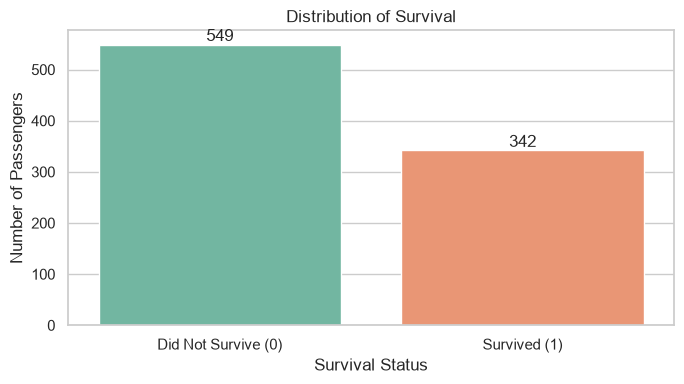

In [24]:
# Calculate class counts and percentages
target_counts = df["Survived"].value_counts().sort_index()
target_percentages = (
    df["Survived"].value_counts(normalize=True).sort_index() * 100
).round(2)

target_summary = pd.DataFrame({
    "Passenger Count": target_counts,
    "Percentage (%)": target_percentages
})

target_summary.index = target_summary.index.map({
    0: "Did Not Survive",
    1: "Survived"
})

display(target_summary)

# Plot target distribution
plt.figure(figsize=(7, 4))
ax = sns.countplot(
    data=df,
    x="Survived",
    hue="Survived",
    order=[0, 1],
    palette="Set2",
    legend=False
)

ax.set_title("Distribution of Survival")
ax.set_xlabel("Survival Status")
ax.set_ylabel("Number of Passengers")
ax.set_xticks([0, 1], ["Did Not Survive (0)", "Survived (1)"])

# Add counts above the bars
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

#### Findings

- **Class balance:**
  - The target variable is moderately imbalanced, with more passengers who did not survive than passengers who survived.

- **Modeling implications:**
  - Accuracy alone may not fully reflect model performance. Additional metrics, such as precision, recall, F1-score, and a confusion matrix, should be considered.
  - Stratified train-validation splitting should be used to preserve similar class proportions in both sets.

## 3. Individual Feature Analysis

### Research Question
How is each feature associated with passenger survival, and which features show patterns that may be useful for predicting survival?

### Objective
Analyze the relationship between each feature and the target variable, `Survived`, using statistical summaries and visualizations appropriate for each feature type. Identify differences in survival rates and feature distributions across passenger groups, while considering missing values, rare categories, and sample sizes. (The findings will guide potential feature engineering and preprocessing decisions, but the predictive value of each feature will ultimately be evaluated during model development.)


##### Categorical Features

For each categorical feature, we will calculate the number of passengers, the number of survivors, and the survival rate in each category, and visualize the survival rates.


Survival Analysis by Sex


,Sex,Passenger_Count,Survivors,Survival_Rate
0,female,314,233,74.20
1,male,577,109,18.89


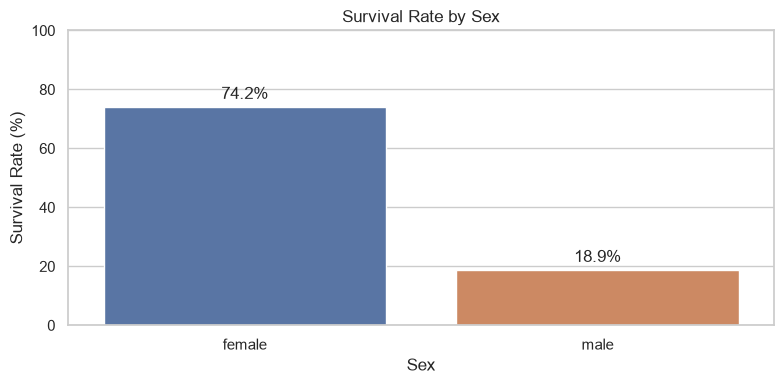


Survival Analysis by Pclass


,Pclass,Passenger_Count,Survivors,Survival_Rate
0,1,216,136,62.96
1,2,184,87,47.28
2,3,491,119,24.24


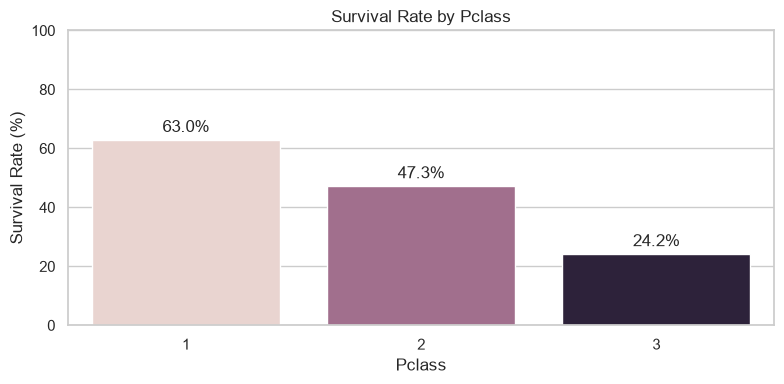


Survival Analysis by Embarked


,Embarked,Passenger_Count,Survivors,Survival_Rate
0,C,168,93,55.36
1,Q,77,30,38.96
2,S,644,217,33.70
3,NaN,2,2,100.00


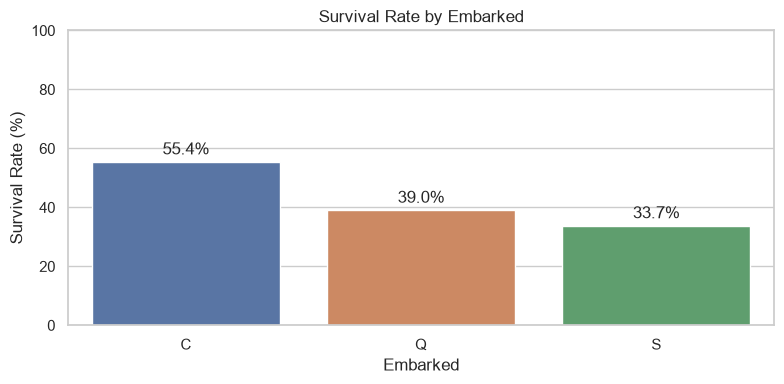

In [25]:
sns.set_theme(style="whitegrid")

def analyze_categorical_feature(data, feature):
    """Summarize and visualize survival rates for a categorical feature."""

    summary = (
        data.groupby(feature, dropna=False, observed=True)
        .agg(
            Passenger_Count=("Survived", "size"),
            Survivors=("Survived", "sum"),
            Survival_Rate=("Survived", "mean")
        )
        .reset_index()
    )

    summary["Survival_Rate"] = (summary["Survival_Rate"] * 100).round(2)

    print(f"\nSurvival Analysis by {feature}")
    display(summary)

    plt.figure(figsize=(8, 4))
    ax = sns.barplot(
        data=summary,
        x=feature,
        y="Survival_Rate",
        hue=feature,
        legend=False,
        errorbar=None
    )

    ax.set_title(f"Survival Rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Survival Rate (%)")
    ax.set_ylim(0, 100)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3)

    plt.tight_layout()
    plt.show()


for feature in ["Sex", "Pclass", "Embarked"]:
    analyze_categorical_feature(df, feature)

##### Numerical Features — Age and Fare
For `Age` and `Fare`, we will use boxplots and histograms to compare the distributions of each feature between passengers who survived and those who did not.

The boxplots will help us compare medians, variability, and potential outliers, while the histograms will help us examine the shapes and overlap of the distributions.

These visualizations will help identify differences between the survival groups and assess whether each feature may provide useful information for predicting passenger survival.

**How to Interpret the Plots**

- **Boxplots:** Compare the medians, interquartile ranges, whiskers, and potential outliers between survivors and non-survivors.
- **Histograms:** Compare the shapes and overlap of the feature distributions. Since the histograms display density, they show the relative distribution of values rather than the number of passengers.
- **Interpretation:** Differences between the distributions may indicate that a feature is associated with survival. However, substantial overlap does not necessarily mean the feature is useless, and these plots alone cannot establish its predictive value or a causal relationship.

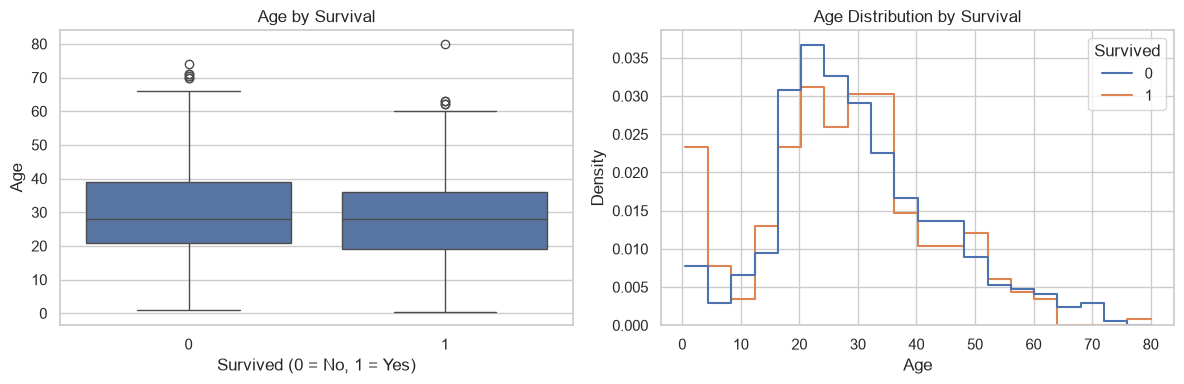

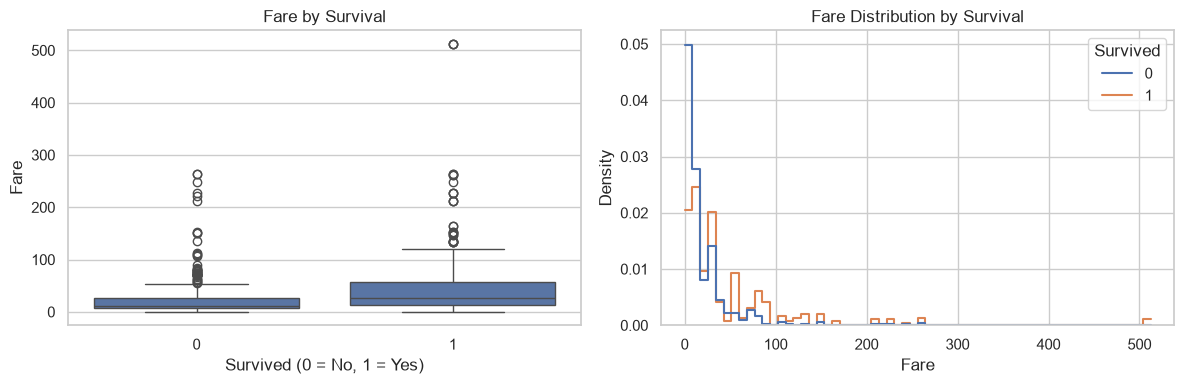

In [26]:
def analyze_continuous_feature(data, feature):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.boxplot(
        data=data,
        x="Survived",
        y=feature,
        ax=axes[0]
    )
    axes[0].set_title(f"{feature} by Survival")
    axes[0].set_xlabel("Survived (0 = No, 1 = Yes)")

    sns.histplot(
        data=data,
        x=feature,
        hue="Survived",
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        ax=axes[1]
    )
    axes[1].set_title(f"{feature} Distribution by Survival")
    axes[1].set_xlabel(feature)

    plt.tight_layout()
    plt.show()


for feature in ["Age", "Fare"]:
    analyze_continuous_feature(df, feature)


#### SibSp and Parch

These features represent the number of siblings/spouses and parents/children aboard. Since they are discrete counts, we will compare survival rates for each observed value.


Survival Analysis by SibSp


,SibSp,Passenger_Count,Survivors,Survival_Rate
0,0,608,210,34.54
1,1,209,112,53.59
2,2,28,13,46.43
3,3,16,4,25.00
4,4,18,3,16.67
5,5,5,0,0.00
6,8,7,0,0.00


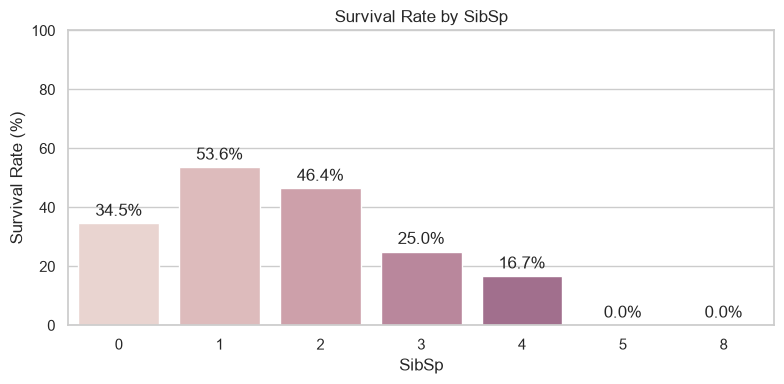


Survival Analysis by Parch


,Parch,Passenger_Count,Survivors,Survival_Rate
0,0,678,233,34.37
1,1,118,65,55.08
2,2,80,40,50.00
3,3,5,3,60.00
4,4,4,0,0.00
5,5,5,1,20.00
6,6,1,0,0.00


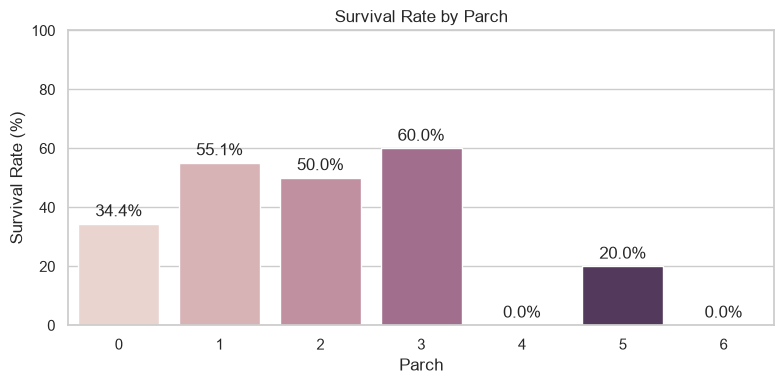

In [27]:
for feature in ["SibSp", "Parch"]:
    analyze_categorical_feature(df, feature)

##### Name — Extracting Passenger Titles
Passenger names may contain titles such as `Mr`, `Mrs`, `Miss`, and `Master`. We will extract these titles and compare their survival rates, To investigate whether the extracted Title feature may provide useful information for predicting passenger survival.

,Title,Passenger_Count,Survivors,Survival_Rate
11,Mr,517,81,15.67
8,Miss,182,127,69.78
12,Mrs,125,99,79.20
7,Master,40,23,57.50
3,Dr,7,3,42.86
14,Rev,6,0,0.00
9,Mlle,2,2,100.00
6,Major,2,1,50.00
1,Col,2,1,50.00
0,Capt,1,0,0.00


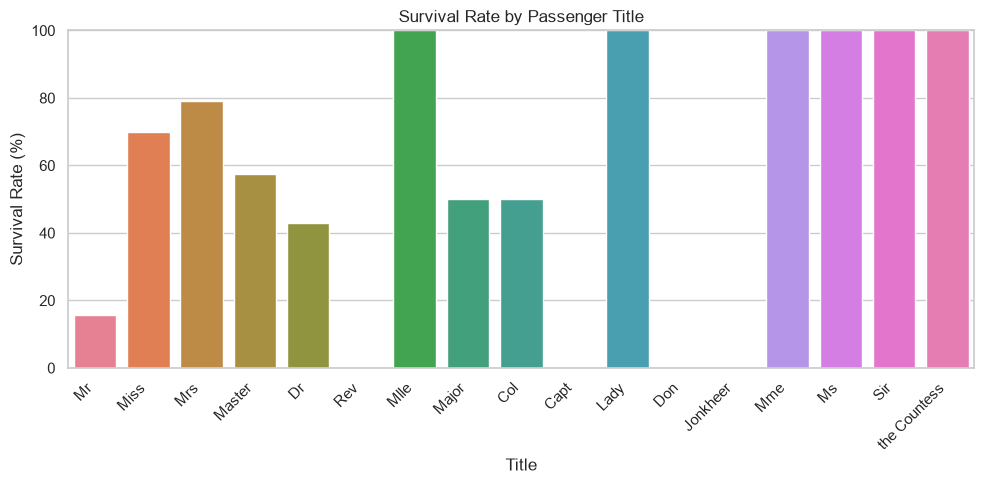

In [28]:
# Extract titles from passenger names
df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.", expand=False)
df["Title"] = df["Title"].str.strip()

title_summary = (
    df.groupby("Title", dropna=False, observed=True)
    .agg(
        Passenger_Count=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
    .reset_index()
)

title_summary["Survival_Rate"] = (title_summary["Survival_Rate"] * 100).round(2)

# Sort by number of passengers to inspect common and rare titles
title_summary = title_summary.sort_values("Passenger_Count",ascending=False)

display(title_summary)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=title_summary,
    x="Title",
    y="Survival_Rate",
    hue="Title",
    legend=False,
    errorbar=None
)

ax.set_title("Survival Rate by Passenger Title")
ax.set_xlabel("Title")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

##### Ticket — Examining Ticket Prefixes

Ticket numbers may contain prefixes that represent shared ticket patterns. We will extract ticket prefixes and compare survival rates across the resulting groups to investigate whether these patterns may provide useful predictive information.


Survival Analysis by Ticket_Prefix


,Ticket_Prefix,Passenger_Count,Survivors,Survival_Rate
0,A,28,2,7.14
1,AS,1,0,0.00
2,C,5,2,40.00
3,CA,41,14,34.15
4,CASOTON,1,0,0.00
5,FA,1,0,0.00
6,FC,1,0,0.00
7,FCC,5,4,80.00
8,LINE,4,1,25.00
9,Numeric Only,661,254,38.43


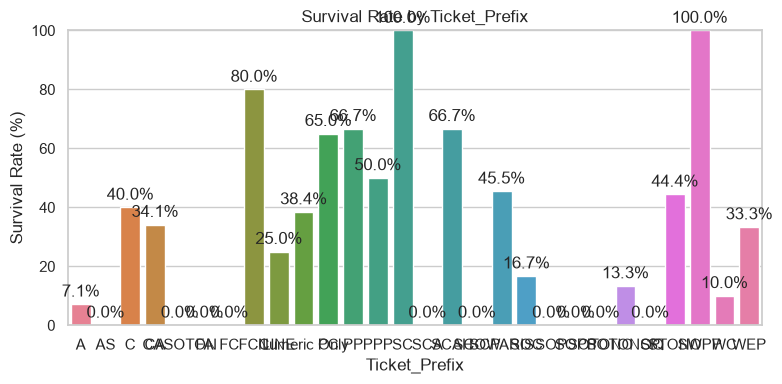

In [29]:
df["Ticket_Prefix"] = (
    df["Ticket"]
    .str.upper()
    .str.replace(r"[/.]", "", regex=True)
    .str.extract(r"^([A-Z]+)", expand=False)
    .fillna("Numeric Only")
)

analyze_categorical_feature(df, "Ticket_Prefix")

##### Cabin — Examining Deck Information and Missingness

The `Cabin` column has many missing values. We will examine whether the presence of a cabin record is associated with survival and, for passengers with a recorded cabin, extract the deck letter.

The `Unknown` group combines passengers whose cabin information is missing. Its survival rate can help us understand whether missingness itself is informative, but it does not establish why the information is missing.


Survival Analysis by Cabin_Recorded


,Cabin_Recorded,Passenger_Count,Survivors,Survival_Rate
0,Missing,687,206,29.99
1,Recorded,204,136,66.67


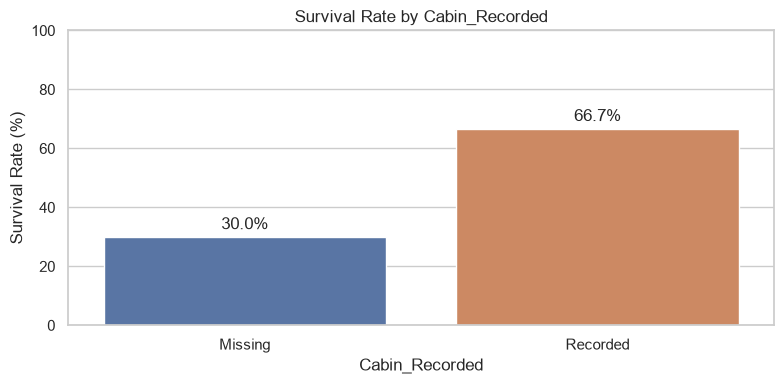

,Deck,Passenger_Count,Survivors,Survival_Rate
8,Unknown,687,206,29.99
2,C,59,35,59.32
1,B,47,35,74.47
3,D,33,25,75.76
4,E,32,24,75.00
0,A,15,7,46.67
5,F,13,8,61.54
6,G,4,2,50.00
7,T,1,0,0.00


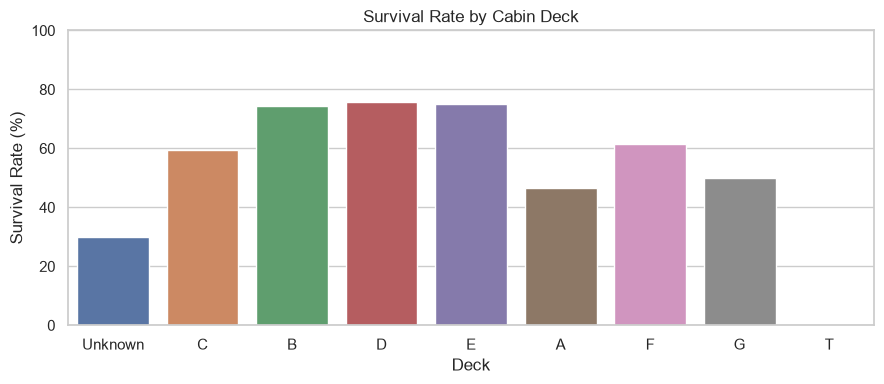

In [30]:
# Check whether a cabin value is recorded
df["Cabin_Recorded"] = df["Cabin"].notna().map({
    True: "Recorded",
    False: "Missing"
})

analyze_categorical_feature(df, "Cabin_Recorded")

# Extract the first cabin letter as the deck
df["Deck"] = df["Cabin"].str[0].fillna("Unknown")

deck_summary = (
    df.groupby("Deck", observed=True)
    .agg(
        Passenger_Count=("Survived", "size"),
        Survivors=("Survived", "sum"),
        Survival_Rate=("Survived", "mean")
    )
    .reset_index()
)

deck_summary["Survival_Rate"] = (
    deck_summary["Survival_Rate"] * 100
).round(2)

deck_summary = deck_summary.sort_values(
    "Passenger_Count",
    ascending=False
)

display(deck_summary)

plt.figure(figsize=(9, 4))
sns.barplot(
    data=deck_summary,
    x="Deck",
    y="Survival_Rate",
    hue="Deck",
    legend=False,
    errorbar=None
)

plt.title("Survival Rate by Cabin Deck")
plt.xlabel("Deck")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

##### SibSp and Parch — Creating FamilySize

The `SibSp` and `Parch` features represent the number of siblings/spouses and parents/children aboard, respectively. We will combine them into a new `FamilySize` feature, including the passenger, and compare survival rates across different family sizes to investigate whether this engineered feature may provide useful information for predicting passenger survival.


Survival Analysis by FamilySize


,FamilySize,Passenger_Count,Survivors,Survival_Rate
0,1,537,163,30.35
1,2,161,89,55.28
2,3,102,59,57.84
3,4,29,21,72.41
4,5,15,3,20.00
5,6,22,3,13.64
6,7,12,4,33.33
7,8,6,0,0.00
8,11,7,0,0.00


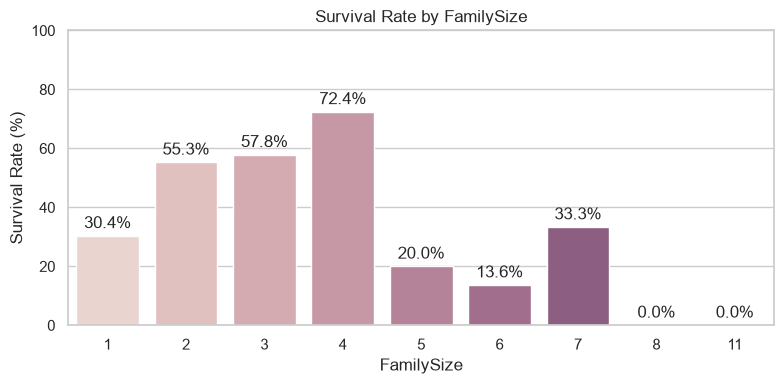

In [31]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

analyze_categorical_feature(df, "FamilySize")

#### Findings

- **Categorical Features:**
  - `Sex`: Female passengers had a substantially higher survival rate (74.20%) than male passengers (18.89%). This suggests that sex may be an informative feature for predicting survival.
  - `Pclass`: First-class passengers had the highest survival rate (62.96%), followed by second-class passengers (47.28%) and third-class passengers (24.24%). Survival rates decreased across the ticket classes, suggesting that passenger class may be an informative feature.
  - `Embarked`: Passengers who embarked at Cherbourg (`C`) had the highest survival rate (55.36%), followed by Queenstown (`Q`, 38.96%) and Southampton (`S`, 33.70%). Only two passengers had missing embarkation information, and both survived. This group is too small to support a reliable conclusion about passengers with missing values.

- **Continuous Numerical Features:**
  - `Age`: The age distributions overlap considerably, with similar median ages (approximately 28) in both groups. Younger passengers may have had higher survival rates, suggesting potential predictive value.
  - `Fare`: Survivors generally paid higher fares, but both distributions are strongly right-skewed with extreme outliers. The substantial overlap suggests that fare alone cannot clearly distinguish survivors from non-survivors.

- **Discrete Numerical Features:**
  - `SibSp`: Passengers traveling with one sibling or spouse had a higher survival rate (53.59%) than passengers traveling without siblings or spouses (34.54%). Survival rates were lower for values of three or more. However, these groups contain relatively few passengers, so their rates should be interpreted cautiously.
  - `Parch`: Passengers traveling with one parent or child had a survival rate of 55.08%, while those traveling with two had a rate of 50.00%. Passengers with no parents or children aboard had a lower rate of 34.37%. Groups with larger values contain very few passengers, making their survival rates less reliable.

- **Textual Features and Derived Representations:**
  - `Title` (Name): Common titles showed different survival rates. Passengers with the titles `Mrs` and `Miss` had higher observed survival rates (79.20% and 69.78%, respectively) than passengers with the title `Mr` (15.67%). However, many titles occur very rarely, so their individual rates are unreliable. Grouping rare titles may be worth investigating during preprocessing.
  - `Ticket_Prefix`: Survival rates varied across ticket prefixes, but many prefixes occurred only a few times. For example, `PC` had a survival rate of 65.00% among 60 passengers, while `Numeric Only` had a rate of 38.43% among 661 passengers. Some other prefixes had very small sample sizes, so their observed rates should not be interpreted as reliable patterns. The usefulness of ticket prefixes requires further evaluation.
  - `Cabin_Recorded`: Passengers with recorded cabin information had a higher survival rate (66.67%) than passengers with missing cabin information (29.99%). This suggests that cabin availability may be informative, although the difference may reflect other passenger characteristics.
  - `Deck`: Observed survival rates were relatively high for decks B (74.47%), D (75.76%), and E (75.00%). However, some decks had very few passengers, so their rates are less reliable. The `Unknown` group had a survival rate of 29.99%, but this represents missing cabin information rather than a known deck.

- **Potential Feature Engineering:**
  - `FamilySize`: Passengers traveling alone had a survival rate of 30.35%, while passengers in families of size 2, 3, and 4 had rates of 55.28%, 57.84%, and 72.41%, respectively. Survival rates were lower for family sizes of 5 and 6, at 20.00% and 13.64%. The pattern is not strictly increasing or decreasing, and the larger-family groups contain relatively few passengers. `FamilySize` may capture useful information, but its additional predictive value should be evaluated during model development.

- **Overall Interpretation:**
  - `Sex` and `Pclass` show substantial differences in observed survival rates and are promising candidate features.
  - `SibSp`, `Parch`, and `FamilySize` show family-related patterns that may be worth exploring further.
  - `Title`, ticket prefixes, and cabin-related features may provide additional information, but rare categories and missing values require careful handling.
  - These findings describe associations in the dataset and do not establish causal relationships. The predictive value of each feature must ultimately be evaluated using a consistent validation procedure.
  


## 4. Numerical Feature Distributions

### Research Question
How are the numerical features distributed ?

### Objective
Examine the distributions and ranges of numerical features to identify differences in scale, skewness, and variability. Use descriptive statistics and visualizations to determine whether transformations, scaling, or other preprocessing steps may be appropriate before model training.


,count,mean,std,min,25%,50%,75%,max,MissingCount,Skewness
Age,714.0,29.699,14.526,0.42,20.125,28.000,38.0,80.000,177,0.389
SibSp,891.0,0.523,1.103,0.00,0.000,0.000,1.0,8.000,0,3.695
Parch,891.0,0.382,0.806,0.00,0.000,0.000,0.0,6.000,0,2.749
Fare,891.0,32.204,49.693,0.00,7.910,14.454,31.0,512.329,0,4.787
FamilySize,891.0,1.905,1.613,1.00,1.000,1.000,2.0,11.000,0,2.727


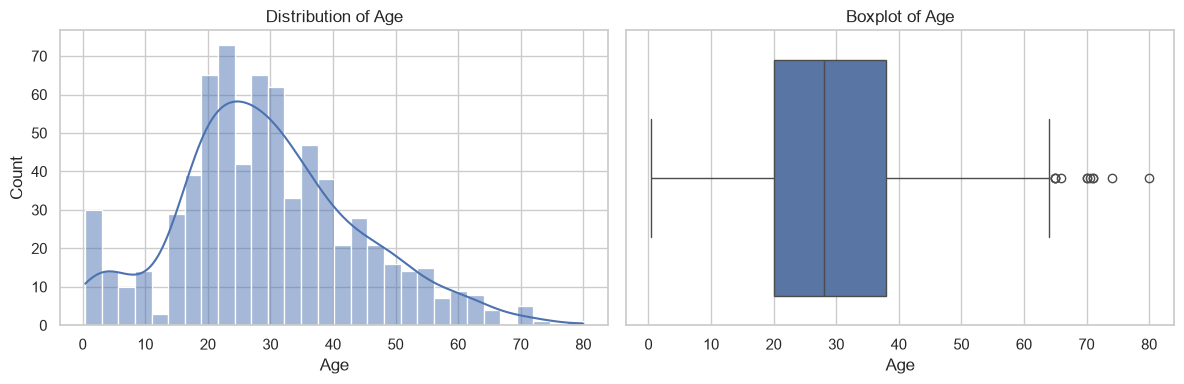

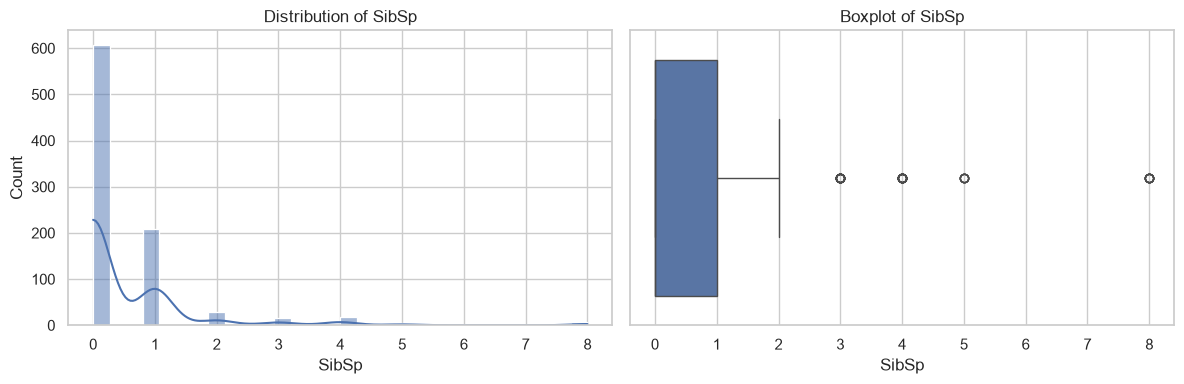

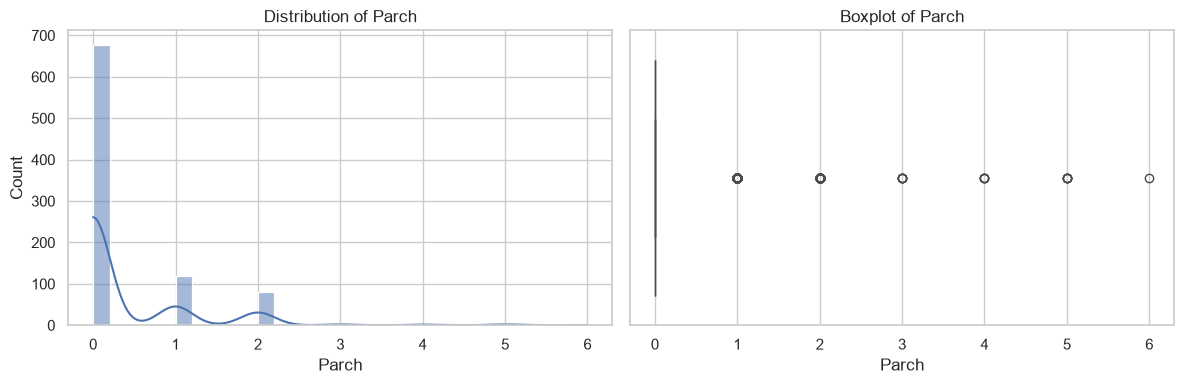

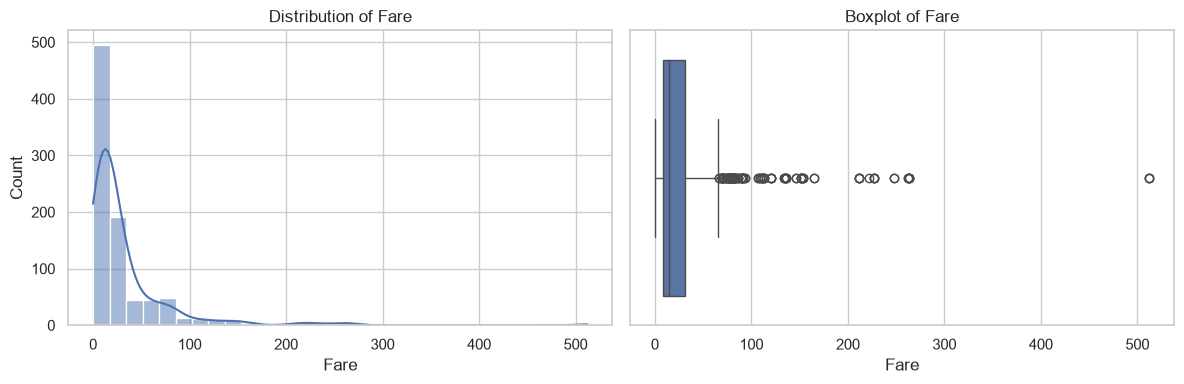

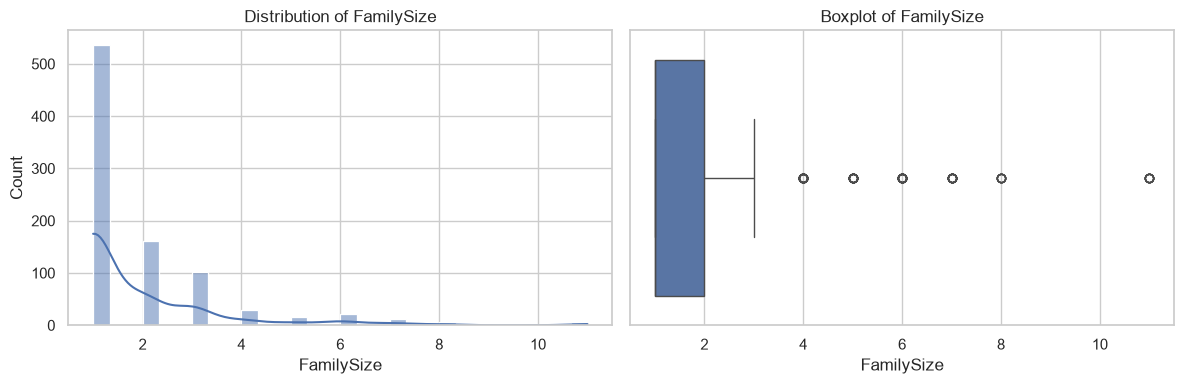

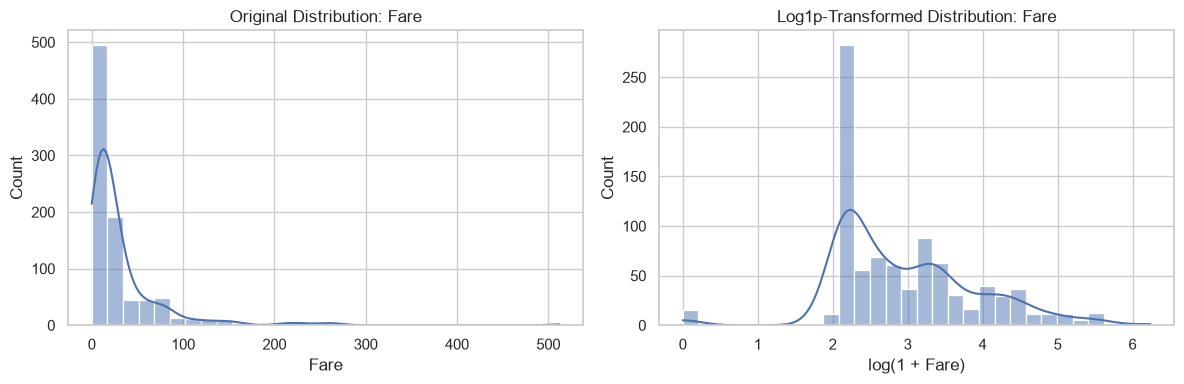

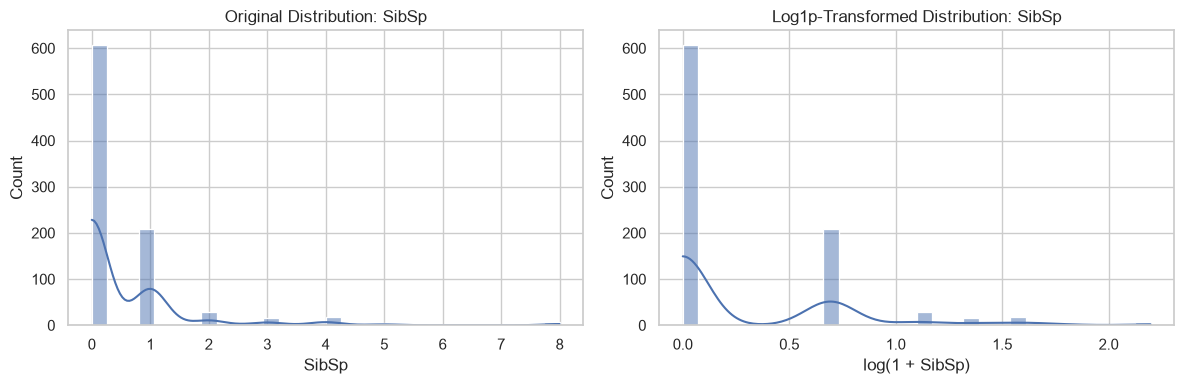

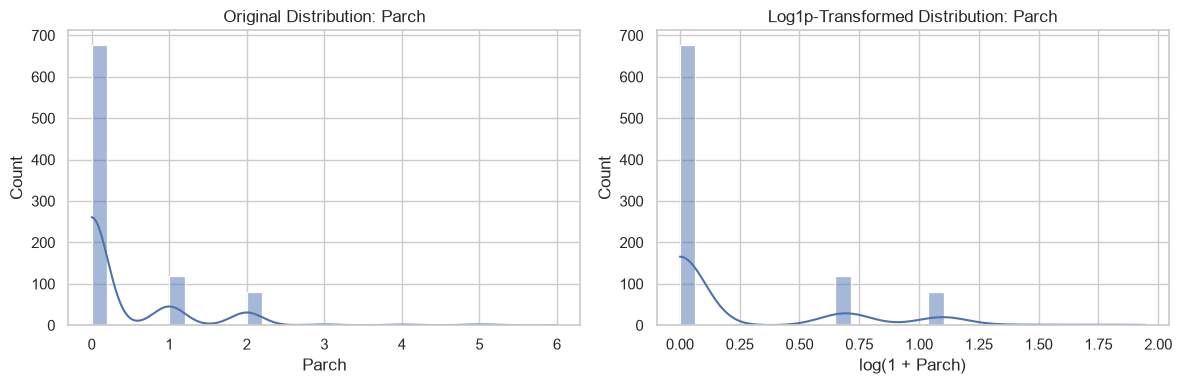

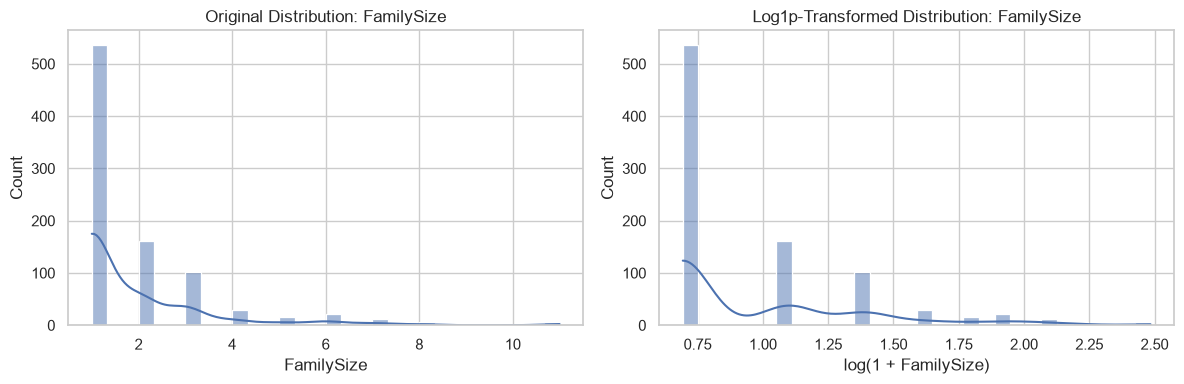

In [32]:



# Prepare numerical features
numerical_df = df.copy()

# Create FamilySize if it has not already been created
if "FamilySize" not in numerical_df.columns:
    numerical_df["FamilySize"] = numerical_df["SibSp"] + numerical_df["Parch"] + 1

numerical_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize"
]

# Descriptive statistics
numerical_summary = numerical_df[numerical_features].describe().T

numerical_summary["MissingCount"] = numerical_df[numerical_features].isna().sum()

numerical_summary["Skewness"] = numerical_df[numerical_features].skew()

display(numerical_summary.round(3))

# Plot histograms and boxplots
for feature in numerical_features:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        data=numerical_df,
        x=feature,
        bins=30,
        kde=True,
        ax=axes[0]
    )
    axes[0].set_title(f"Distribution of {feature}")
    axes[0].set_xlabel(feature)
    axes[0].set_ylabel("Count")

    sns.boxplot(
        data=numerical_df,
        x=feature,
        ax=axes[1]
    )
    axes[1].set_title(f"Boxplot of {feature}")
    axes[1].set_xlabel(feature)

    plt.tight_layout()
    plt.show()


# Compare original and log-transformed distributions
# Use log1p only for non-negative features that may be right-skewed
log_features = ["Fare", "SibSp", "Parch", "FamilySize"]

for feature in log_features:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        data=numerical_df,
        x=feature,
        bins=30,
        kde=True,
        ax=axes[0]
    )
    axes[0].set_title(f"Original Distribution: {feature}")
    axes[0].set_xlabel(feature)

    transformed_values = np.log1p(
        numerical_df[feature].dropna()
    )

    sns.histplot(
        x=transformed_values,
        bins=30,
        kde=True,
        ax=axes[1]
    )
    axes[1].set_title(f"Log1p-Transformed Distribution: {feature}")
    axes[1].set_xlabel(f"log(1 + {feature})")

    plt.tight_layout()
    plt.show()



#### Findings

- **Distribution shape:**
  - `Fare`, `SibSp`, `Parch`, and `FamilySize` are right-skewed, while `Age` is more approximately normally distributed.
  - `Fare` has a wide range of values compared to the other numerical features.

- **Preprocessing implications:**
  - A `log1p` transformation may be useful for `Fare` to reduce skewness.
  - Feature scaling may be needed depending on the model. `Age` also requires missing-value imputation.



## 5. Data Validation & Outlier Analysis

### Research Question
Does the dataset contain invalid values, statistically unusual observations, or rare categories that require further investigation?

### Objective
Validate data consistency and identify potentially problematic or unusual observations according to feature type. For continuous numerical features, check logical value ranges and detect statistical outliers. For discrete numerical features, verify valid integer values and identify unusually rare counts. For categorical features, validate category values and identify rare categories with limited observations.

The goal is to distinguish data errors from valid but uncommon observations and determine whether any special preprocessing is necessary.

##### Continuous Numerical Features

In [33]:
continuous_features = ["Age", "Fare"]

for col in continuous_features:
    values = df[col].dropna()

    print(f"\n--- {col} ---")
    print(f"Missing values: {df[col].isna().sum()}")
    print(f"Minimum value: {values.min()}")
    print(f"Maximum value: {values.max()}")

    if col == "Age":
        invalid = df[col].notna() & ((df[col] < 0) | (df[col] > 120))
        print(f"Values outside the expected range [0, 120]: {invalid.sum()}")

    elif col == "Fare":
        invalid = df[col].notna() & (df[col] < 0)
        print(f"Negative values: {invalid.sum()}")

    if invalid.any():
        print("Potentially invalid values:")
        print(df.loc[invalid, ["PassengerId", col]])


--- Age ---
Missing values: 177
Minimum value: 0.42
Maximum value: 80.0
Values outside the expected range [0, 120]: 0

--- Fare ---
Missing values: 0
Minimum value: 0.0
Maximum value: 512.3292
Negative values: 0



--- Age ---
Lower bound: -6.69
Upper bound: 64.81
Number of outliers: 11
Outlier values:
[65.0, 65.0, 65.0, 66.0, 70.0, 70.0, 70.5, 71.0, 71.0, 74.0, 80.0]

--- Fare ---
Lower bound: -26.72
Upper bound: 65.63
Number of outliers: 116
Outlier values:
[66.6, 66.6, 69.3, 69.3, 69.55, 69.55, 69.55, 69.55, 69.55, 69.55, 69.55, 71.0, 71.0, 71.2833, 73.5, 73.5, 73.5, 73.5, 73.5, 75.25, 76.2917, 76.7292, 76.7292, 76.7292, 77.2875, 77.2875, 77.9583, 77.9583, 77.9583, 78.2667, 78.2667, 78.85, 78.85, 79.2, 79.2, 79.2, 79.2, 79.65, 79.65, 79.65, 80.0, 80.0, 81.8583, 82.1708, 82.1708, 83.1583, 83.1583, 83.1583, 83.475, 83.475, 86.5, 86.5, 86.5, 89.1042, 89.1042, 90.0, 90.0, 90.0, 90.0, 91.0792, 91.0792, 93.5, 93.5, 106.425, 106.425, 108.9, 108.9, 110.8833, 110.8833, 110.8833, 110.8833, 113.275, 113.275, 113.275, 120.0, 120.0, 120.0, 120.0, 133.65, 133.65, 134.5, 134.5, 135.6333, 135.6333, 135.6333, 146.5208, 146.5208, 151.55, 151.55, 151.55, 151.55, 153.4625, 153.4625, 153.4625, 164.8667, 164.8667,

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,Age,-6.6875,64.8125,11,1.540616
1,Fare,-26.7240,65.6344,116,13.019080


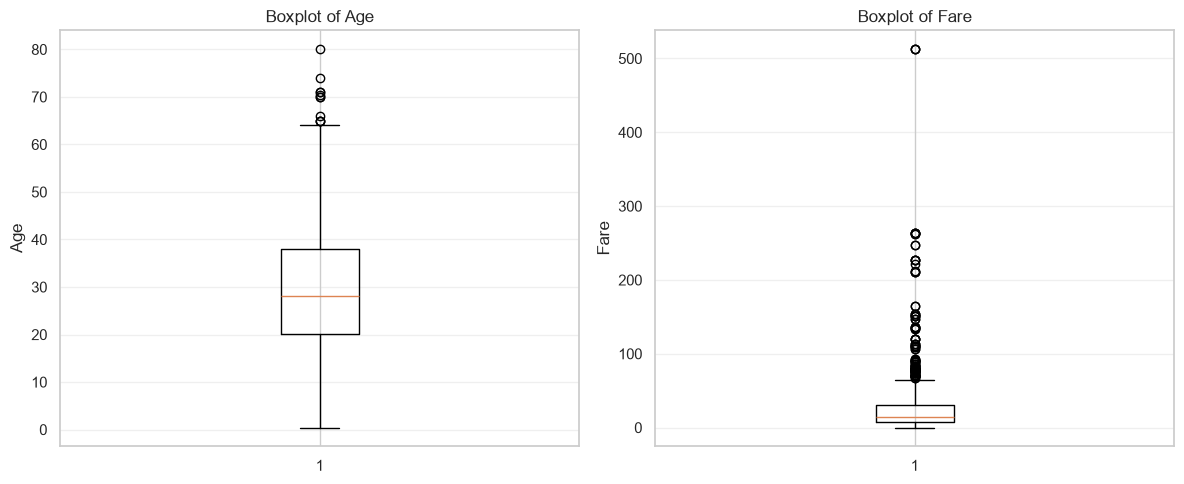

In [34]:
outlier_results = []

for col in continuous_features:
    values = df[col].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[(values < lower_bound) | (values > upper_bound)]

    outlier_results.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage (%)": len(outliers) / len(values) * 100
    })

    print(f"\n--- {col} ---")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Number of outliers: {len(outliers)}")

    if not outliers.empty:
        print("Outlier values:")
        print(outliers.sort_values().to_list())

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, continuous_features):
    ax.boxplot(df[col].dropna())
    ax.set_title(f"Boxplot of {col}")
    ax.set_ylabel(col)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

##### Discrete Numerical Features

In [35]:
discrete_features = ["SibSp", "Parch"]

for col in discrete_features:
    values = df[col].dropna()

    invalid = (
        (df[col].notna())
        & ((df[col] < 0) | (df[col] % 1 != 0))
    )

    print(f"\n--- {col} ---")
    print(f"Missing values: {df[col].isna().sum()}")
    print(f"Minimum value: {values.min()}")
    print(f"Maximum value: {values.max()}")
    print(f"Negative or non-integer values: {invalid.sum()}")

    if invalid.any():
        print("Potentially invalid values:")
        print(df.loc[invalid, ["PassengerId", col]])


--- SibSp ---
Missing values: 0
Minimum value: 0
Maximum value: 8
Negative or non-integer values: 0

--- Parch ---
Missing values: 0
Minimum value: 0
Maximum value: 6
Negative or non-integer values: 0



--- Frequency distribution of SibSp ---


,SibSp,Count,Percentage (%)
0,0,608,68.24
1,1,209,23.46
2,2,28,3.14
3,3,16,1.80
4,4,18,2.02
5,5,5,0.56
6,8,7,0.79


Values appearing in fewer than 10 observations:


,SibSp,Count,Percentage (%)
5,5,5,0.56
6,8,7,0.79



--- Frequency distribution of Parch ---


,Parch,Count,Percentage (%)
0,0,678,76.09
1,1,118,13.24
2,2,80,8.98
3,3,5,0.56
4,4,4,0.45
5,5,5,0.56
6,6,1,0.11


Values appearing in fewer than 10 observations:


,Parch,Count,Percentage (%)
3,3,5,0.56
4,4,4,0.45
5,5,5,0.56
6,6,1,0.11


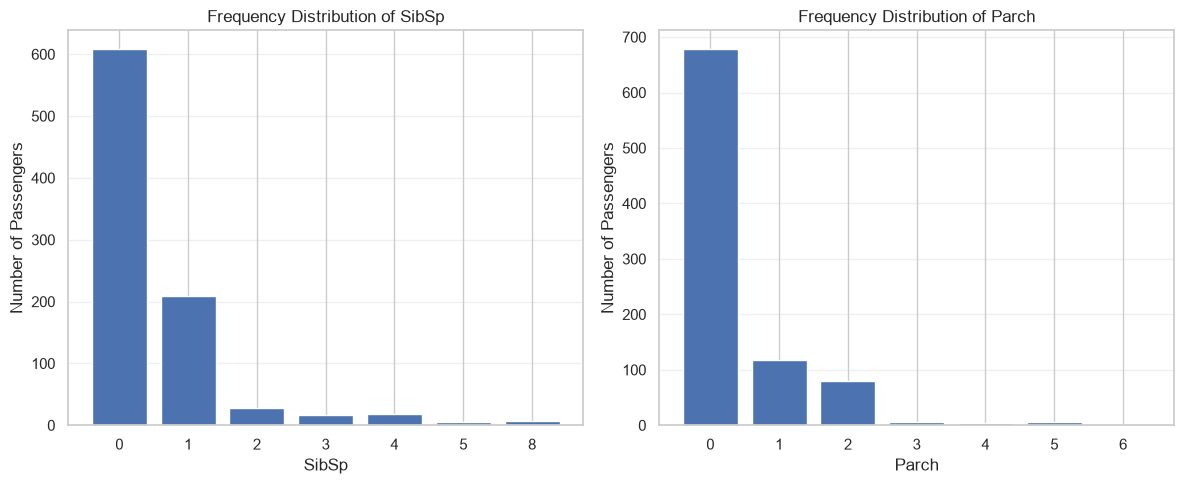

In [36]:
for col in discrete_features:
    print(f"\n--- Frequency distribution of {col} ---")

    frequency = (
        df[col]
        .value_counts(dropna=False)
        .sort_index()
        .rename_axis(col)
        .reset_index(name="Count")
    )

    frequency["Percentage (%)"] = (
        frequency["Count"] / len(df) * 100
    ).round(2)

    display(frequency)

    # Values appearing in fewer than 10 observations
    rare_values = frequency[
        frequency["Count"] < 10
    ]

    print("Values appearing in fewer than 10 observations:")
    display(rare_values)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, discrete_features):
    counts = df[col].value_counts().sort_index()

    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(f"Frequency Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Passengers")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

##### Categorical Features

In [37]:
categorical_features = {
    "Sex": ["male", "female"],
    "Embarked": ["C", "Q", "S"],
    "Pclass": [1, 2, 3]
}

for col, expected_categories in categorical_features.items():
    invalid = (
        df[col].notna()
        & ~df[col].isin(expected_categories)
    )

    print(f"\n--- {col} ---")
    print(f"Missing values: {df[col].isna().sum()}")
    print(f"Expected categories: {expected_categories}")
    print(f"Unexpected values: {invalid.sum()}")

    if invalid.any():
        print("Unexpected category values:")
        print(df.loc[invalid, ["PassengerId", col]])


--- Sex ---
Missing values: 0
Expected categories: ['male', 'female']
Unexpected values: 0

--- Embarked ---
Missing values: 2
Expected categories: ['C', 'Q', 'S']
Unexpected values: 0

--- Pclass ---
Missing values: 0
Expected categories: [1, 2, 3]
Unexpected values: 0



--- Frequency distribution of Sex ---


,Sex,Count,Percentage (%)
0,male,577,64.76
1,female,314,35.24


Categories appearing in fewer than 10 observations:


,Sex,Count,Percentage (%)



--- Frequency distribution of Embarked ---


...

,Embarked,Count,Percentage (%)
3,NaN,2,0.22



--- Frequency distribution of Pclass ---


,Pclass,Count,Percentage (%)
0,3,491,55.11
1,1,216,24.24
2,2,184,20.65


Categories appearing in fewer than 10 observations:


,Pclass,Count,Percentage (%)


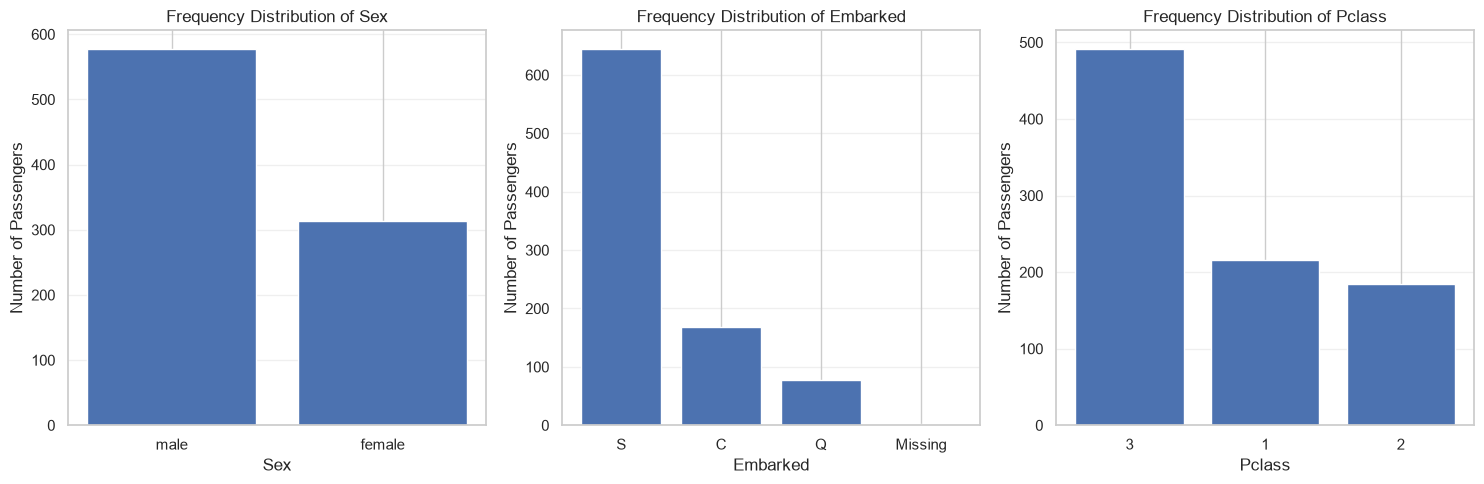

In [38]:
for col in categorical_features:
    print(f"\n--- Frequency distribution of {col} ---")

    frequency = (
        df[col]
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="Count")
    )

    frequency["Percentage (%)"] = (
        frequency["Count"] / len(df) * 100
    ).round(2)

    display(frequency)

    # Identify categories appearing in fewer than 10 observations
    rare_categories = frequency[
        frequency["Count"] < 10
    ]

    print("Categories appearing in fewer than 10 observations:")
    display(rare_categories)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, categorical_features):
    counts = df[col].value_counts(dropna=False)

    # Convert all category labels to strings, including missing values
    labels = [
        "Missing" if pd.isna(value) else str(value)
        for value in counts.index
    ]

    ax.bar(range(len(counts)), counts.values)
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(labels)

    ax.set_title(f"Frequency Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Passengers")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Findings

- **Data validity:** No invalid values were found.
- **Outliers:** The IQR method identified 11 outliers in `Age` and 116 in `Fare`. These values appear plausible and may reflect genuine differences between passengers, particularly in ticket prices. No outlier removal is currently justified.

- **Rare values:** Some values of `SibSp` and `Parch` occur infrequently, potentially representing passengers traveling with larger families. 

- **Preprocessing implications:** The identified outliers and rare values should be retained unless further investigation indicates data errors.

## Preprocessing Considerations

Based on the EDA findings, the following preprocessing steps should be considered before model development:

- **Missing Values:** Impute missing values in `Age` and `Embarked`. Since `Cabin` has a high proportion of missing values (77.10%), consider creating a missingness indicator and extracting deck information from available cabin records rather than relying solely on the raw column.

- **Feature Engineering:** Consider retaining or creating derived features such as `Title` and `FamilySize`. Evaluate whether ticket prefixes provide additional predictive value. Exclude `PassengerId` from model inputs because it serves as an identifier, and exclude `Name`, `Ticket`, and `Cabin` in their raw forms if their useful information is represented through derived features.

- **Categorical Encoding:** Encode categorical features such as `Sex`, `Embarked`, and `Pclass`, as well as any derived categorical features retained for modeling. Rare categories may be grouped where appropriate to reduce sparsity.

- **Numerical Features:** Consider applying a `log1p` transformation to `Fare` to reduce right skewness. Feature scaling may be required depending on the selected model. The appropriate treatment of `Age` should also account for its missing values.

- **Outliers and Rare Values:** Retain plausible outliers in `Age` and `Fare`, as well as rare values in `SibSp` and `Parch`, unless further investigation reveals data errors. Avoid removing observations solely because they are statistically unusual or infrequent.